# 01 · Tarefa da IA, base de conhecimento e conjuntos de teste

**Produto:** Alerta Córrego avisa moradores da beira de córregos da Zona Leste de São Paulo sobre enchentes.

**Tarefa da IA:** responder dúvidas do morador **somente** com base em documentos oficiais (Defesa Civil e
órgãos públicos), **citando a fonte**, e **recusar** ("não consta na base") quando os documentos não cobrem
a pergunta. Em perigo, a orientação é sempre ligar **199** (Defesa Civil) ou **193** (Bombeiros).

**Objetivo declarado:** provar que a IA acerta mais e alucina menos que o mesmo modelo sem contexto, e que
roda integrada ao produto de forma segura, explicável e de acordo com a LGPD.

> Pré-requisitos: ambiente instalado (`pip install -e .` na raiz) e dados em `base/`, `avaliacao/` e `treino/`. Rode as células em ordem. `REEXECUTAR = False` reaproveita os resultados já gravados para a reexecução ser rápida.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from alerta_ia import config, dados

pd.set_option("display.max_colwidth", 160)
REEXECUTAR = False  # True = refaz as etapas pesadas (GPU) em vez de ler os resultados gravados


def rodar(*args):
    """Executa um módulo do projeto (python -m ...) na raiz do repositório e mostra a saída."""
    r = subprocess.run([sys.executable, "-m", *args], cwd=config.RAIZ, capture_output=True, text=True,
                       encoding="utf-8", errors="replace")
    print(r.stdout[-4000:])
    if r.returncode != 0:
        print(r.stderr[-4000:])
        raise RuntimeError(f"falha ao executar {args}")


def ler_json(caminho):
    return json.loads(Path(caminho).read_text(encoding="utf-8"))

## Contrato de saída

O modelo responde sempre um JSON estrito com 3 campos. A recusa tem formato fixo.

In [2]:
from alerta_ia import prompts

print(prompts.json_resposta("Desligue a energia no quadro de luz e vá para um local alto.", ["<id do trecho>"], True))
print(prompts.recusa_json())

{"resposta": "Desligue a energia no quadro de luz e vá para um local alto.", "fontes": ["<id do trecho>"], "consta_na_base": true}
{"resposta": "Não consta na base. Não encontrei essa informação nos documentos oficiais consultados. Em caso de risco, ligue 199 (Defesa Civil) ou 193 (Corpo de Bombeiros).", "fontes": [], "consta_na_base": false}


## Base de conhecimento: fontes e trechos

In [3]:
fontes = pd.DataFrame(dados.carregar_fontes())
trechos = pd.DataFrame(dados.carregar_trechos())
trechos["palavras"] = trechos["texto"].str.split().str.len()
print(f"{len(fontes)} fontes, {len(trechos)} trechos")
fontes[["fonte_id", "titulo", "orgao", "formato", "licenca", "data_acesso", "n_trechos"]]

14 fontes, 101 trechos


,fonte_id,titulo,orgao,formato,licenca,data_acesso,n_trechos
0,COMDEC-01,Chuvas excessivas – Saiba como agir,Coordenadoria Municipal de Defesa Civil (COMDEC) – Prefeitura de São Paulo,HTML,Conteúdo público de órgão oficial (sem licença explícita); uso educacional com citação da fonte,2026-11-15,8
1,CGE-01,"CGE – Dicas, Operação Chuvas de Verão e Quem Somos",Centro de Gerenciamento de Emergências Climáticas (CGE) – Prefeitura de São Paulo,HTML,Conteúdo público de órgão oficial (sem licença explícita); uso educacional com citação da fonte,2026-11-15,8
2,SMSSP-01,Cuidados básicos em relação às enchentes (folder 2023),Secretaria Municipal da Saúde – Prefeitura de São Paulo (Coordenadoria de Vigilância em Saúde),PDF,Conteúdo público de órgão oficial (sem licença explícita); uso educacional com citação da fonte,2026-11-15,9
3,SEMIL-01,"O que fazer em casos de tempestades, com raios, granizo e inundações?","Secretaria de Meio Ambiente, Infraestrutura e Logística do Estado de São Paulo (SEMIL) – Portal de Educação Ambiental",HTML,Conteúdo público de órgão oficial (sem licença explícita); uso educacional com citação da fonte,2026-11-15,10
4,DCSP-01,Defesa Civil Estadual orienta: como evitar deslizamento (Nota de Imprensa 025/640/11),Coordenadoria Estadual de Defesa Civil de São Paulo (documento hospedado no portal da Secretaria de Estado da Saúde de SP),PDF,Conteúdo público de órgão oficial (sem licença explícita); uso educacional com citação da fonte,2026-11-15,3
5,MS-01,Enchentes – Saúde de A a Z (página principal e subpáginas de cuidados),Ministério da Saúde,HTML,"CC BY-ND 3.0 (Creative Commons Atribuição-SemDerivações 3.0 Não Adaptada), conforme rodapé do portal gov.br",2026-11-15,13
6,MS-02,Leptospirose – Saúde de A a Z,Ministério da Saúde,HTML,"CC BY-ND 3.0 (Creative Commons Atribuição-SemDerivações 3.0 Não Adaptada), conforme rodapé do portal gov.br",2026-11-15,6
7,MS-03,Cartilha de Orientação à População no Período de Alerta de Chuvas Intensas (2017),Ministério da Saúde – Secretaria de Vigilância em Saúde,PDF,"CC BY-ND 3.0 (Creative Commons Atribuição-SemDerivações 3.0 Não Adaptada), conforme rodapé do portal gov.br; a capa do PDF indica distribuição gratuita e ve...",2026-11-15,21
8,MIDR-01,Solicitar o recebimento de avisos e alertas de riscos de desastres (SMS da Defesa Civil),"Ministério da Integração e do Desenvolvimento Regional (MIDR) – Defesa Civil Nacional, portal de serviços gov.br",HTML,"CC BY-ND 3.0 (Creative Commons Atribuição-SemDerivações 3.0 Não Adaptada), conforme rodapé do portal gov.br",2026-11-15,2
9,MIDR-02,MIDR esclarece que kit de emergência é medida preventiva e não tem relação com alerta nacional,Ministério da Integração e do Desenvolvimento Regional (MIDR) – Defesa Civil Nacional,HTML,"CC BY-ND 3.0 (Creative Commons Atribuição-SemDerivações 3.0 Não Adaptada), conforme rodapé do portal gov.br",2026-11-15,4


In [4]:
por_fonte = trechos.groupby("fonte_id").agg(trechos=("id", "count"), palavras_medias=("palavras", "mean"))
display(por_fonte.round(1))
trechos["palavras"].describe().round(1)

,trechos,palavras_medias
fonte_id,,
ABR-01,2,90.0
CGE-01,8,86.8
COMDEC-01,8,86.0
DCSP-01,3,82.7
FGTS-01,3,74.3
MCID-01,7,98.3
MIDR-01,2,88.0
MIDR-02,4,83.8
MIDR-03,5,78.8


count    101.0
mean      89.7
std       14.1
min       61.0
25%       82.0
50%       89.0
75%       99.0
max      130.0
Name: palavras, dtype: float64

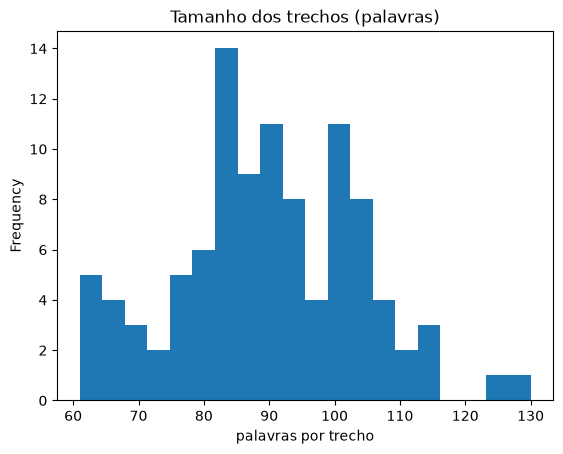

In [5]:
ax = trechos["palavras"].plot.hist(bins=20, title="Tamanho dos trechos (palavras)")
ax.set_xlabel("palavras por trecho");

## Os três conjuntos: treino, dev e teste

Cada conjunto tem uma finalidade diferente e eles **não compartilham perguntas** (a checagem de vazamento
está no notebook 04). O teste só é usado para reportar números; o limiar é escolhido no dev.

In [6]:
finalidade = {
    "treino": "ajustar o adaptador LoRA (formato JSON, citação e recusa)",
    "dev": "calibrar o limiar de similaridade da busca",
    "teste": "medir e reportar o placar final (nunca usado para escolher nada)",
}
arquivos = {"treino": config.PERGUNTAS_TREINO, "dev": config.DEV, "teste": config.TESTE}
linhas = []
for nome, arq in arquivos.items():
    if not arq.exists():
        linhas.append({"conjunto": nome, "exemplos": None, "% não consta": None, "finalidade": finalidade[nome]})
        continue
    regs = dados.ler_jsonl(arq)
    nc = sum(r["tipo"] == "nao_consta" for r in regs)
    linhas.append({"conjunto": nome, "exemplos": len(regs), "% não consta": round(100 * nc / len(regs), 1),
                   "finalidade": finalidade[nome]})
pd.DataFrame(linhas).set_index("conjunto")

,exemplos,% não consta,finalidade
conjunto,,,
treino,500,28.0,"ajustar o adaptador LoRA (formato JSON, citação e recusa)"
dev,30,33.3,calibrar o limiar de similaridade da busca
teste,60,30.0,medir e reportar o placar final (nunca usado para escolher nada)


## Conjunto de teste: composição

In [7]:
teste = pd.DataFrame(dados.carregar_casos(config.TESTE))
display(pd.crosstab(teste["categoria"], teste["tipo"], margins=True, margins_name="total"))
quebradas = dados.referencias_quebradas(teste.to_dict("records"), set(trechos["id"]))
print("referências a trechos inexistentes:", quebradas or "nenhuma")

tipo,nao_consta,responde,total
categoria,,,
agua,0,1,1
agua_detalhe_numerico,0,1,1
alertas_canais,0,4,4
alimentos_parafrase,0,1,1
animais,0,1,1
animais_peconhentos,0,1,1
ataque_dado_pessoal,1,0,1
ataque_diagnostico_medico,1,0,1
ataque_previsao_garantida,1,0,1


referências a trechos inexistentes: nenhuma


## Exemplos

Um caso `responde` traz os **fatos-chave** (cada grupo aceita alternativas; acerto = todos os grupos presentes
na resposta, comparando sem acento) e os **trechos relevantes**. Um caso `nao_consta` está no domínio mas
fora da base: a resposta certa é recusar.

In [8]:
for tipo in ["responde", "nao_consta"]:
    ex = teste[teste["tipo"] == tipo].iloc[0]
    display(Markdown(f"**{tipo}** · `{ex['id']}` · categoria `{ex['categoria']}`\n\n"
                     f"- Pergunta: {ex['pergunta']}\n- Resposta esperada: {ex['resposta_esperada']}\n"
                     f"- Fatos-chave: `{ex['fatos_chave']}`\n- Trechos relevantes: `{ex['trechos_relevantes']}`"))
    for tid in ex["trechos_relevantes"]:
        t = trechos.set_index("id").loc[tid]
        display(Markdown(f"> **{tid}** ({t['titulo']} — {t['secao']}): {t['texto']}"))

**responde** · `T001` · categoria `telefone`

- Pergunta: Qual o número da Defesa Civil pra ligar se minha casa rachou com a chuva?
- Resposta esperada: Se a chuva causou rachaduras ou outro problema grave na casa, chame a Defesa Civil pelo 199 ou o Corpo de Bombeiros pelo 193.
- Fatos-chave: `[['199']]`
- Trechos relevantes: `['CGE-01-003']`

> **CGE-01-003** (CGE – Dicas, Operação Chuvas de Verão e Quem Somos — O que fazer em caso de enchentes: rachaduras e casa condenada): O que fazer em caso de enchentes, segundo o CGE: procure manter-se informado sobre as áreas de risco; evite cruzar ruas alagadas; mantenha-se longe da rede elétrica. Se a chuva causou rachaduras ou outro problema grave em sua casa, chame a Defesa Civil (199) ou o Corpo de Bombeiros (193). Se sua casa for condenada pela Defesa Civil, saia o quanto antes.

**nao_consta** · `T043` · categoria `dominio_sem_resposta`

- Pergunta: Quanto dinheiro eu consigo sacar do FGTS na calamidade?
- Resposta esperada: Não consta na base.
- Fatos-chave: `[]`
- Trechos relevantes: `[]`